# 15: A causal rule detector, tested like a real alarm

**Goal:** turn the skeleton rules of notebook 10 into a **real-time alarm**. The detector reads the video frame by frame, uses **only past frames**, and must raise the alarm **within 3 s of the fall starting**.

**Why a new notebook?** Notebook 10 answers *"does this whole video contain a fall?"* after watching it to the end. A real alarm system must decide **while** the video plays. So we change two things:

| | Notebook 10 (offline) | This notebook (real time) |
|---|---|---|
| What is scored | one answer per video | **each alarm**, with its time |
| A fall counts as caught if | any alarm in the video | the first alarm comes within **3 s after the fall starts** |
| False alarm | an ADL video with an alarm | **every** alarm in an ADL, and every alarm **before** the fall starts |
| Train / test split | thresholds chosen on all 70 videos | **leave one subject out**: thresholds chosen on 4 groups, tested on the 5th |

**Fall start (onset):** the first frame labelled *falling* (label 0) in the dataset.

**Pose:** two extractors, cached once by `scripts/extract_poses.py`: **MediaPipe** (as in notebook 09) and **YOLO11m-pose**. Both give the 17 COCO joints and a person box.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from fallcv import m1, pose, rule, urfd, windows
from fallcv.eval import evaluate, video_level

lab, onsets = urfd.labels(), urfd.fall_onsets()
groups = m1.load_groups()
seqs = urfd.sequences()
EXTRACTORS = ["mediapipe", "yolo"]
poses = {e: {s: pose.load(e, s) for s in seqs} for e in EXTRACTORS}
print(len(seqs), "videos,", len(onsets), "falls,", sum(len(poses["mediapipe"][s][0]) for s in seqs), "frames")

70 videos, 30 falls, 11936 frames


💡 **Interpretation:** 70 videos (30 falls, 40 daily activities), 11,936 frames. The skeletons come from the cache, so nothing is re-detected here; `m1` is only used to read the groups file.

## Step 1: The 5 groups (leave one subject out)

`annotations/subjects.csv` puts every video in one of **5 groups**:
- **falls:** 5 actors, 6 videos each (`fall-01`…`06` = actor 1, and so on);
- **ADLs:** the actors are not labelled, so we group by **recording session** (same room and light).

In each round we keep one group out for testing. A person is therefore **never** in training and test at the same time, which is what happens with a new user.

In [2]:
g = groups.reset_index()
g["kind"] = g.seq.str.split("-").str[0]
table = g.groupby(["group", "kind"]).seq.agg(lambda s: f"{s.iloc[0]} … {s.iloc[-1]} ({len(s)})").unstack()
table

kind,adl,fall
group,,
1,adl-01 … adl-11 (11),fall-01 … fall-06 (6)
2,adl-12 … adl-23 (12),fall-07 … fall-12 (6)
3,adl-24 … adl-29 (6),fall-13 … fall-18 (6)
4,adl-30 … adl-40 (6),fall-19 … fall-24 (6)
5,adl-31 … adl-35 (5),fall-25 … fall-30 (6)


💡 **Interpretation:** every group holds **6 falls of one actor** plus one ADL recording session. Group 4 is `adl-30` and `adl-36`…`40`, group 5 is `adl-31`…`35` (the table shows only the first and last name). Each round trains on about 56 videos and tests on 14.

## Step 2: The state machine, frame by frame

The rules live in `src/fallcv/rule.py` (same idea as notebook 10, written to run live):

```
STANDING / WALKING / SITTING ──(rapid descent)──▶ FALLING ──(down for 0.3 s)──▶ LYING ──(still down 0.5 s)──▶ FALL_DETECTED
```

Per frame it measures, from the skeleton and the box:

| Signal | Meaning |
|---|---|
| **ratio** | box height / the person's own **upright height** (learnt while they stand): 1 = standing, below 0.4 = on the floor |
| **angle** | torso angle with the vertical: 0° upright, 90° flat |
| **v_down** | downward speed of the hips, in body heights per second |
| **d_ratio, d_angle** | how much height / angle was lost in the last 0.6 s |

**Rapid descent** = fast hips, **or** a big height loss, **or** a big rotation. Height loss matters for falls **towards the camera**, where the hips barely move in the image. Reaching the floor **slowly** ends in LYING **without** alarm (lying down on purpose).

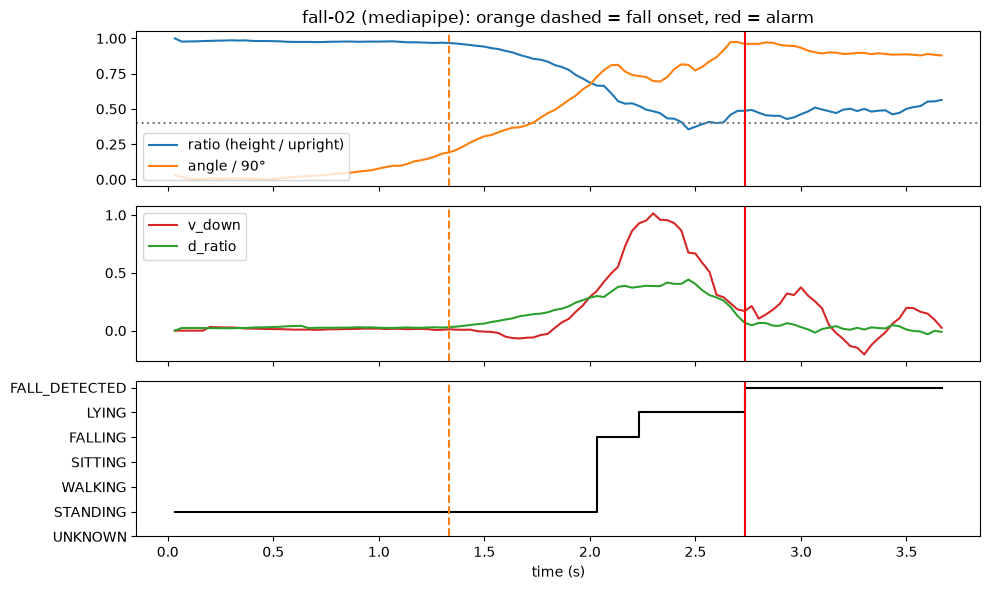

alarms (frame): [82]


In [3]:
STATE_Y = {s: i for i, s in enumerate(rule.STATES)}

def timeline(seq, extractor="mediapipe"):
    kp, box = poses[extractor][seq]
    states, alarms, feats = rule.run(kp, box)
    t = np.arange(1, len(states) + 1) / urfd.FPS
    get = lambda k: np.array([f[k] if f and f.get(k) is not None else np.nan for f in feats], float)
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    ax[0].plot(t, get("ratio"), label="ratio (height / upright)"); ax[0].axhline(0.4, ls=":", c="grey")
    ax[0].plot(t, get("angle") / 90, label="angle / 90°"); ax[0].legend(loc="lower left")
    ax[1].plot(t, get("v_down"), c="C3", label="v_down"); ax[1].plot(t, get("d_ratio"), c="C2", label="d_ratio")
    ax[1].legend(loc="upper left")
    ax[2].step(t, [STATE_Y[s] for s in states], where="post", c="k")
    ax[2].set_yticks(range(len(rule.STATES)), rule.STATES)
    for a in ax:
        if seq in onsets: a.axvline(onsets[seq] / urfd.FPS, c="C1", ls="--")
        for al in alarms: a.axvline(al / urfd.FPS, c="red")
    ax[0].set_title(f"{seq} ({extractor}): orange dashed = fall onset, red = alarm")
    ax[2].set_xlabel("time (s)")
    plt.tight_layout(); plt.show()
    return alarms

print("alarms (frame):", timeline("fall-02"))

💡 **Interpretation:** the story of a fall in four lines: the torso starts to tilt at the onset (1.3 s), the body loses height and speeds down (v_down peaks at ≈ 1.0 body height per second at 2.3 s), the machine goes FALLING at 2.0 s, LYING at 2.2 s and raises the alarm at **2.7 s, 1.4 s after the onset**. Note that the ratio stops at ≈ 0.45 instead of near 0: the person probably fell towards the camera, so the box stays fairly tall. That is why the rule also accepts a big rotation as a *rapid descent*.

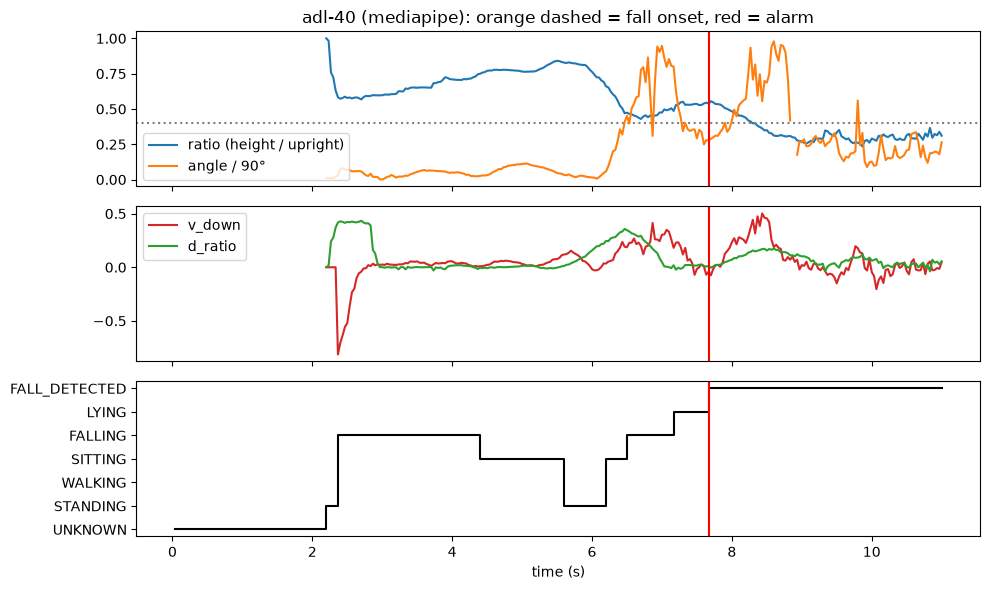

alarms (frame): [230]


In [4]:
print("alarms (frame):", timeline("adl-40"))

💡 **Interpretation:** a **false alarm**: in `adl-40` the person lies down on purpose. The first upright height is learnt while the person is still entering the image (ratio jumps from 1.0 to 0.6 at 2.3 s), so the rule believes they are already half down and enters FALLING. Later, the torso swings flat quickly (angle spikes to 90°) and the machine accepts it as a fall. A wrong reference height is a weakness of hand-written rules: every later threshold depends on it.

## Step 3: All 70 videos with the hand-picked thresholds

First with the default thresholds of `rule.Params()` (chosen by hand while building the rules, so slightly optimistic). We report both scores: the **real-time** one and the **offline video** one of notebooks 02-10.

In [5]:
def run_all(extractor, p=rule.Params()):
    return {s: rule.run(kp, box, p)[:2] for s, (kp, box) in poses[extractor].items()}

KEEP = ["falls_hit", "adl_false_alarms", "fa_per_hour_adl", "pre_onset_false_alarms", "median_latency_s"]
rows = []
for e in EXTRACTORS:
    res = run_all(e)
    _, s = evaluate(res, onsets, lab)
    rows.append({"extractor": e, **{k: s[k] for k in KEEP}, **video_level(res)})
pd.DataFrame(rows).round(3)

,extractor,falls_hit,adl_false_alarms,fa_per_hour_adl,pre_onset_false_alarms,median_latency_s,videos_right,video_accuracy,falls_caught,adl_videos_alarmed
0,mediapipe,17/30,10,120.792,0,1.4,47/70,0.671,17/30,10/40
1,yolo,13/30,11,132.871,0,1.6,42/70,0.600,13/30,11/40


💡 **Interpretation:** with the hand-picked thresholds only **17 of 30 falls (MediaPipe) and 13 (YOLO)** raise the alarm in time, with 10 and 11 false alarms (about 120 per hour of daily activity). At video level that is 47/70, far from the 64/70 of notebook 10: notebook 10 sees the **whole** video and smooths the signals with a centred median (it uses future frames), while here each decision only uses the past. No alarm comes **before** an onset; the missed falls raise **no alarm at all**.

## Step 4: Fair thresholds: chosen on 4 groups, tested on the 5th

We try 9 settings of the two most important thresholds (`drop_ratio`: how much height must be lost, `confirm_s`: how long the person must stay down). In each round the setting with the best *falls caught − false alarms* **on the 4 training groups** is applied to the test group.

In [6]:
GRID = [replace(rule.Params(), drop_ratio=d, confirm_s=c) for d in [0.3, 0.4, 0.5] for c in [0.3, 0.5, 1.0]]

def b0_loso(extractor):
    runs = [run_all(extractor, p) for p in GRID]
    merged, rows = {}, []
    for g in sorted(groups.unique()):
        train = [s for s in seqs if groups[s] != g]
        def score(r):
            d = evaluate({s: r[s] for s in train}, onsets, lab)[0]
            return d.hit.fillna(False).astype(int).sum() - d.false_alarms.sum()
        best = max(range(len(GRID)), key=lambda i: score(runs[i]))
        test = {s: runs[best][s] for s in seqs if groups[s] == g}
        merged.update(test)
        _, s = evaluate(test, onsets, lab)
        rows.append(dict(group=g, drop_ratio=GRID[best].drop_ratio, confirm_s=GRID[best].confirm_s,
                         falls_hit=s["falls_hit"], recall=s["event_recall"], adl_false_alarms=s["adl_false_alarms"]))
    return merged, pd.DataFrame(rows)

b0 = {}
for e in EXTRACTORS:
    b0[e], folds = b0_loso(e)
    print(e); display(folds.round(2))

mediapipe


,group,drop_ratio,confirm_s,falls_hit,recall,adl_false_alarms
0,1,0.5,0.3,5/6,0.83,0
1,2,0.5,0.3,6/6,1.00,0
2,3,0.5,0.3,2/6,0.33,0
3,4,0.5,0.3,4/6,0.67,4
4,5,0.5,0.3,2/6,0.33,3


yolo


,group,drop_ratio,confirm_s,falls_hit,recall,adl_false_alarms
0,1,0.5,0.3,5/6,0.83,0
1,2,0.5,0.3,6/6,1.00,3
2,3,0.5,0.3,0/6,0.00,0
3,4,0.4,0.3,2/6,0.33,4
4,5,0.5,0.3,1/6,0.17,4


💡 **Interpretation:** almost every round picks the same setting (`drop_ratio` 0.5, `confirm_s` 0.3 s), so the choice is stable. The spread between groups is huge though: group 2 gets 6/6, group 3 and 5 only 2/6 (MediaPipe) or 0 to 1/6 (YOLO). The rule works for some actors and fails completely for others.

In [7]:
rows = []
for e in EXTRACTORS:
    per_seq, s = evaluate(b0[e], onsets, lab)
    rec = per_seq[per_seq.kind == "fall"].assign(g=lambda d: d.seq.map(groups)).groupby("g").hit.mean()
    rows.append({"extractor": e, **{k: s[k] for k in KEEP}, "recall mean ± std": f"{rec.mean():.2f} ± {rec.std():.2f}",
                 **video_level(b0[e])})
b0_table = pd.DataFrame(rows).round(3)
b0_table

,extractor,falls_hit,adl_false_alarms,fa_per_hour_adl,pre_onset_false_alarms,median_latency_s,recall mean ± std,videos_right,video_accuracy,falls_caught,adl_videos_alarmed
0,mediapipe,19/30,7,84.554,0,1.200,0.63 ± 0.30,52/70,0.743,19/30,7/40
1,yolo,14/30,11,132.871,0,1.417,0.47 ± 0.43,43/70,0.614,14/30,11/40


💡 **Interpretation:** the fair score of the rule is **19/30 falls with 7 false alarms (MediaPipe)**, recall 0.63 ± 0.30 across the 5 actors, and **14/30 with 11 false alarms (YOLO)**. Median latency 1.2 s. The very large ± shows how much hand thresholds depend on the person. MediaPipe is better than YOLO for the rule.

## Step 5: Which videos are wrong, and why?

For every missed fall we also measure how often the pose model **found the person while lying** (label 1 frames): a rule cannot see a fall that the pose model does not see.

In [8]:
def lying_seen(extractor, seq):
    kp, _ = poses[extractor][seq]
    f = lab[(lab.seq == seq) & (lab.label == 1)].frame.values - 1
    return np.mean(~np.isnan(kp[f, 11, 0])) if len(f) else np.nan

per_seq, _ = evaluate(b0["mediapipe"], onsets, lab)
missed = per_seq[(per_seq.kind == "fall") & ~per_seq.hit.astype(bool)].copy()
missed["group"] = missed.seq.map(groups)
missed["lying frames with a skeleton"] = [lying_seen("mediapipe", s) for s in missed.seq]
missed["first alarm after onset (s)"] = missed.latency_s
missed[["seq", "group", "n_alarms", "lying frames with a skeleton", "first alarm after onset (s)"]].round(2)

,seq,group,n_alarms,lying frames with a skeleton,first alarm after onset (s)
11,fall-01,1,0,0.94,NaN
41,fall-13,3,0,1.00,NaN
42,fall-14,3,0,1.00,NaN
43,fall-15,3,0,0.57,NaN
45,fall-17,3,0,0.00,NaN
55,fall-21,4,0,0.20,NaN
57,fall-23,4,0,0.74,NaN
64,fall-25,5,0,0.00,NaN
66,fall-27,5,0,0.08,NaN
68,fall-29,5,0,0.05,NaN


💡 **Interpretation:** two kinds of misses. **The pose model loses the person** on the floor: `fall-17`, `25`, `27`, `29` have a skeleton on 0 to 8% of the lying frames, so no rule can work there. **The rule misses a visible fall**: `fall-01`, `13`, `14` keep a skeleton on 94 to 100% of lying frames, but the descent does not cross the hand-picked thresholds. The second kind is exactly what a learned model can fix (notebook 16).

ADLs with an alarm: adl-36, adl-37, adl-39, adl-40, adl-32, adl-33, adl-35


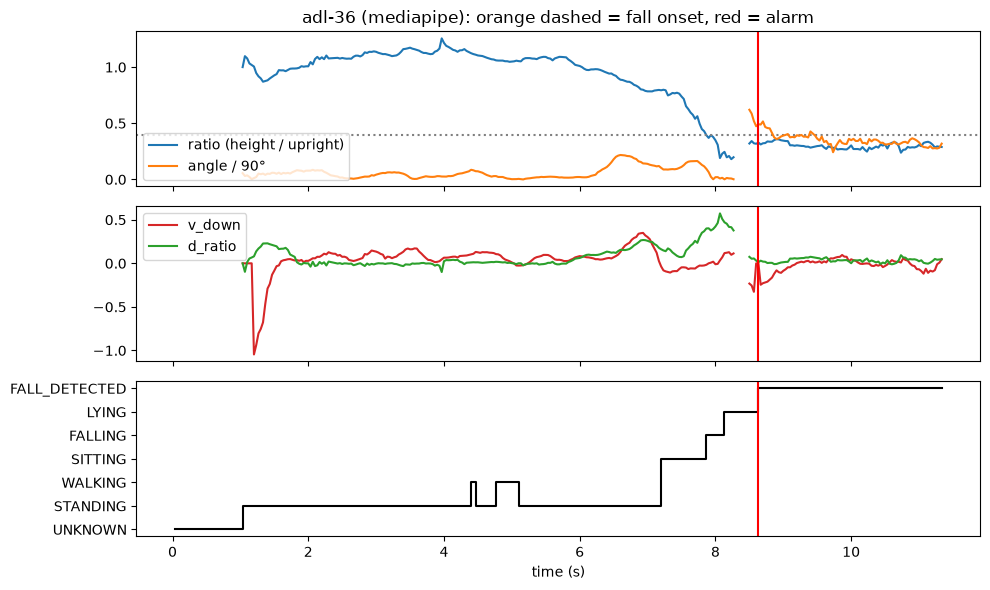

alarms (frame): [259]


In [9]:
fa = per_seq[(per_seq.kind == "adl") & (per_seq.false_alarms > 0)]
print("ADLs with an alarm:", ", ".join(fa.seq))
print("alarms (frame):", timeline(fa.seq.iloc[0]))

💡 **Interpretation:** the 7 false alarms are all in groups 4 and 5, the sessions where people **go down to the floor on purpose** (kneeling, crawling, lying). In `adl-36` the person sits, goes down and the rule accepts it 8.6 s in: going down fairly fast and staying there *is* a fall for the rules, the same limit as in notebook 10.

## What we learned

1. **Real time is harder than offline.** The same idea that catches 30/30 falls in notebook 10 catches only **19/30 in time** once it may use only past frames and must alarm within 3 s.
2. **Fair test:** thresholds chosen on 4 actors and tested on the 5th give **19/30 falls, 7 false alarms (MediaPipe)**, with a recall of 0.63 ± 0.30: the rule works well for some people and fails for others.
3. **MediaPipe beats YOLO** for this rule (19 vs 14 falls).
4. **Two causes of misses:** the pose model loses the person on the floor (4 falls), or the fall is visible but does not match the hand thresholds (the rest). Only the second can be fixed by a better decision.
5. **False alarms** come from people going down to the floor on purpose, and from a wrong upright reference height.

**Next notebook (16):** keep the same signals and the same real-time test, but **learn** the decision with a classifier.